In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [3]:
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [8]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DnF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [5]:
for i in range(len(NL)):
    print(i,NL[i]['name'])

0 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_158uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_158uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_158uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_158uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_158uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_158uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_158uWperArm_Rmp100Hz
10 Night_2_1MhzGate_158uWperArm_Rmp10Hz
11 Night_2_1MhzGate_158uWperArm_Rmp1Hz
12 Night_2_1MhzGate_158uWperArm_Rmp1Hz


In [7]:
NL[0]

{'name': 'Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp',
 'timestamp': datetime.datetime(2025, 11, 28, 18, 7, 58, tzinfo=datetime.timezone.utc),
 'npz_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp_20251128T180758+0000.npz',
 'csv_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp_20251128T180758+0000.csv',
 'meta_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp_20251128T180758+0000_meta.txt',
 'data': {'timestamps': array(['2025-11-28T18:07:59.085259000', '2025-11-28T18:07:59.085359000',
         '2025-11-28T18:07:59.085459000', ...,
         '2025-11-28T18:11:19.084959000', '2025-11-28T18:11:19.085059000',
         '2025-11-28T18:11:19.085159000'], dtype='datetime64[ns]'),
  'counts': array([3, 3, 2, ..., 2, 3, 3], dtype=uint32),
  'voa_volts': array([0., 0., 0., ..., 5., 5., 5.]),
  'pm_volts': array([1.

In [7]:
for i in range(len(NLF)):
    print(i,NLF[i]['name'])

0 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_voaramp
1 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_voaramp
2 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_voaramp
3 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_voaramp
4 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_nomodulation
5 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_nomodulation
6 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_nomodulation
7 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_nomodulation
8 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz
9 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz
10 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz
11 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz
12 NightFast_2_1MhzGate_158uWperArm_Rmp1Hz


In [9]:
for i in range(len(NLVF)):
    print(i,NLVF[i]['name'])

0 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_voaramp
1 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_voaramp
2 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_voaramp
3 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_voaramp
4 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_nomodulation
5 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_nomodulation
6 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_nomodulation
7 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_nomodulation
8 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz
9 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz
10 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz
11 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz
12 NightVeryFast_2_1MhzGate_145uWperArm_Rmp1Hz


In [6]:
measure=ms
index=8
f_ramp=1000.0
n_taus=10
tau_max=5.0
log_bins=True
overlap=0.5
phase_offset=0.0
n_min=20
verbose=True
NNFtaus, NNFvmax, NNFvmin, NNFvmean = Vis.VisLockAnalysis(measure, index, 
                    f_ramp,
                    n_taus,
                    tau_max,
                    log_bins,
                    overlap,
                    phase_offset,
                    n_min,
                    verbose)

8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 3.000e-04 s (K=   3, overlap_eff=0.33) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[2] = 1.100e-03 s (K=  11, overlap_eff=0.45) -> 333329 windows, V_max= 1.0000, V_min= 0.1916, V_mean= 0.7115
τ[3] = 3.700e-03 s (K=  37, overlap_eff=0.51) -> 111110 windows, V_max= 1.0000, V_min= 0.3891, V_mean= 0.6999
τ[4] = 1.230e-02 s (K= 123, overlap_eff=0.50) -> 32257 windows, V_max= 0.8586, V_min= 0.5528, V_mean= 0.6961
τ[5] = 4.080e-02 s (K= 408, overlap_eff=0.50) -> 9802 windows, V_max= 0.7787, V_min= 0.6038, V_mean= 0.6921
τ[6] = 1.357e-01 s (K=1357, overlap_eff=0.50) -> 2948 windows, V_max= 0.7306, V_min= 0.4663, V_mean= 0.6704
τ[7] = 4.516e-01 s (K=4516, overlap_eff=0.50) ->  884 windows, V_max= 0.7050, V_min= 0.1257, V_mean= 0.5893
τ[8] = 1.503e+00 s (K=15027, overlap_eff=0.50) ->  265 windows, V_max= 0.6523, V_min= 0.0062, V_mean= 0.4119

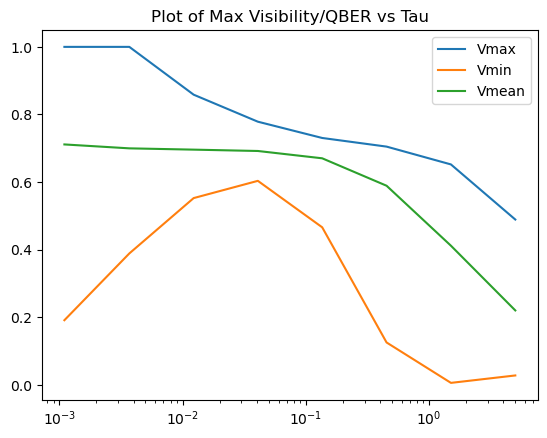

In [9]:
plt.semilogx(NNFtaus,NNFvmax,label='Vmax')
plt.semilogx(NNFtaus,NNFvmin,label='Vmin')
plt.semilogx(NNFtaus,NNFvmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

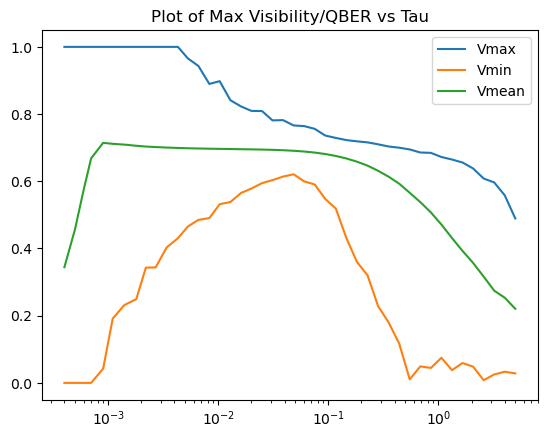

In [25]:
plt.semilogx(NNFtaus,NNFvmax,label='Vmax')
plt.semilogx(NNFtaus,NNFvmin,label='Vmin')
plt.semilogx(NNFtaus,NNFvmean,label='Vmean')
plt.title('Plot of Max Visibility/QBER vs Tau')
#plt.axvline(tau, color='gray', linestyle='--')
plt.legend()

In [11]:
def AnalyseMeasurement2(ms,i,n_taus,tau,phase_length,firsthalf=True,secondhalf=True):
    measure=ms
    index=8
    f_ramp=1/phase_length
    n_taus=20
    tau_max=5.0
    log_bins=True
    overlap=0.5
    phase_offset=0.0
    n_min=20
    verbose=True
    print(i,ms[i]['name'])
    ts=Vis.timestamps_to_elapsed_seconds(ms[i]['data']['timestamps'])
    cts=ms[i]['data']['counts']
    taus, Vmax, Vmin, Vmean = Vis.lockin_visibility_vs_tau(
        ts,
        cts,
        f_ramp,
        n_taus,
        tau_max,
        log_bins,
        overlap,
        phase_offset,
        n_min,
        verbose)
    if firsthalf==True:
        fig1,axes1 = plt.subplots(ncols=2,figsize=(14, 3))
        axes1[0].semilogx(taus,Vmax,label='Vmax')
        axes1[0].semilogx(taus,Vmin,label='Vmin')
        axes1[0].semilogx(taus,Vmean,label='Vmean')
        axes1[0].set_title('Plot of Visibility vs Tau')
        axes1[0].axvline(tau, color='gray', linestyle='--')
        axes1[0].legend()
        axes1[0].set_ylim(0,1.05)
    ts_b, counts_b, meta = Vis.bin_by_tau_point(ts, cts, tau, ts_mode="start", include_partial="normalize")
    if firsthalf==True:
        axes1[1].plot(ts_b,counts_b,color='tab:orange')
        axes1[1].set_title('Plot of Counts vs Time, binned at Tau')
        axes1[1].set_ylim(0,np.max(counts_b))
    tsrv, Vrv, Vrver=Vis.lockin_visibility_vs_time(ts, cts,f_ramp, tau, n_min=n_min, clip=True)
    QBERrv=(1-Vrv)/2
    QBERrver=0.5*Vrver
    if secondhalf==True:
        fig2,axes2 = plt.subplots(ncols=2,figsize=(14, 3))
        axes2[0].scatter(tsrv,Vrv,color='tab:blue')
        axes2[0].errorbar(tsrv,Vrv,yerr=Vrver,color='tab:green', alpha=0.1)
        axes2[0].set_title('Plot of Visibility vs Time, binned at Tau')
        axes2[0].set_ylim(0.2,1.05)
        axes2[1].errorbar(tsrv,QBERrv,yerr=QBERrver,color='red', alpha=0.1)
        axes2[1].scatter(tsrv,QBERrv,color='tab:green')
        axes2[1].set_title('Plot of QBER vs Time, binned at Tau')
        axes2[1].set_ylim(0,0.5)
    pb_vis=[taus, Vmax, Vmin]
    bn_b_tau=[ts_b, counts_b, meta]
    roll_vis=[tsrv, Vrv, Vrver,QBERrv,QBERrver]
    values=[pb_vis,bn_b_tau,roll_vis]
    return(values)

In [7]:
def AnalyseMeasurement2_fast(ms,i,n_taus,tau,phase_length,firsthalf=True,secondhalf=True):
    measure=ms
    index=8
    f_ramp=1/phase_length
    n_taus=20
    tau_max=5.0
    log_bins=True
    overlap=0.5
    phase_offset=0.0
    n_min=20
    verbose=True
    print(i,ms[i]['name'])
    ts=Vis.timestamps_to_elapsed_seconds(ms[i]['data']['timestamps'])
    cts=ms[i]['data']['counts']
    taus, Vmax, Vmin, Vmean = Vis.lockin_visibility_vs_tau_fast(
        ts,
        cts,
        f_ramp,
        n_taus,
        tau_max,
        log_bins,
        overlap,
        phase_offset,
        n_min,
        verbose)
    if firsthalf==True:
        fig1,axes1 = plt.subplots(ncols=2,figsize=(14, 3))
        axes1[0].semilogx(taus,Vmax,label='Vmax')
        axes1[0].semilogx(taus,Vmin,label='Vmin')
        axes1[0].semilogx(taus,Vmean,label='Vmean')
        axes1[0].set_title('Plot of Visibility vs Tau')
        axes1[0].axvline(tau, color='gray', linestyle='--')
        axes1[0].legend()
        axes1[0].set_ylim(0,1.05)
    ts_b, counts_b, meta = Vis.bin_by_tau_point(ts, cts, tau, ts_mode="start", include_partial="normalize")
    if firsthalf==True:
        axes1[1].plot(ts_b,counts_b,color='tab:orange')
        axes1[1].set_title('Plot of Counts vs Time, binned at Tau')
        axes1[1].set_ylim(0,np.max(counts_b))
    tsrv, Vrv, Vrver=Vis.lockin_visibility_vs_time_fast(ts, cts,f_ramp, tau, n_min=n_min, clip=True)
    QBERrv=(1-Vrv)/2
    QBERrver=0.5*Vrver
    if secondhalf==True:
        fig2,axes2 = plt.subplots(ncols=2,figsize=(14, 3))
        axes2[0].scatter(tsrv,Vrv,color='tab:blue')
        axes2[0].errorbar(tsrv,Vrv,yerr=Vrver,color='tab:green', alpha=0.1)
        axes2[0].set_title('Plot of Visibility vs Time, binned at Tau')
        axes2[0].set_ylim(0.2,1.05)
        axes2[1].errorbar(tsrv,QBERrv,yerr=QBERrver,color='red', alpha=0.1)
        axes2[1].scatter(tsrv,QBERrv,color='tab:green')
        axes2[1].set_title('Plot of QBER vs Time, binned at Tau')
        axes2[1].set_ylim(0,0.5)
    pb_vis=[taus, Vmax, Vmin]
    bn_b_tau=[ts_b, counts_b, meta]
    roll_vis=[tsrv, Vrv, Vrver,QBERrv,QBERrver]
    values=[pb_vis,bn_b_tau,roll_vis]
    return(values)

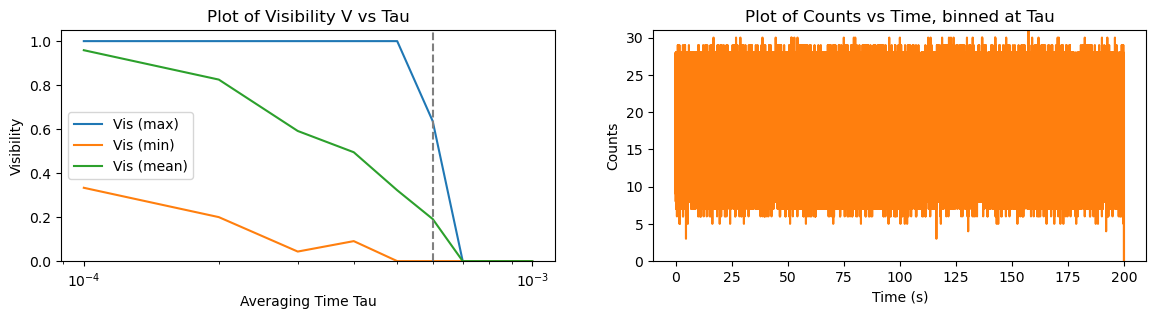

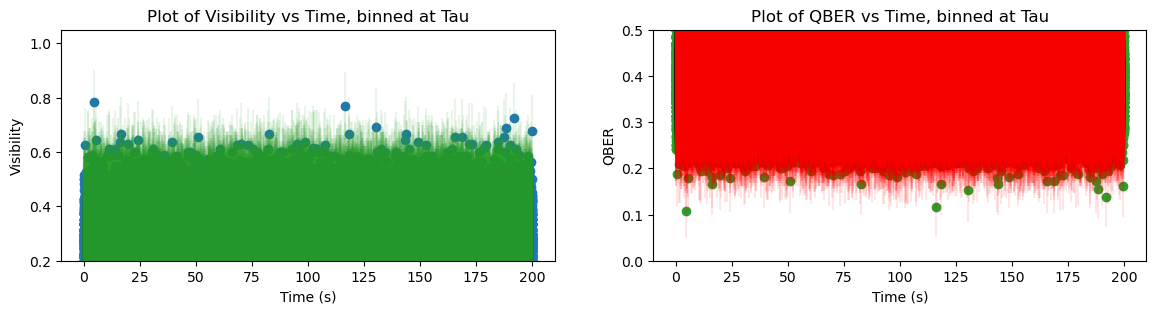

In [7]:
values1=Vis.AnalyseMeasurement(ms,8,100,0.0006,0.001,secondhalf=True)

In [7]:
tau_max=5.0
log_bins=True
overlap=0.5
phase_offset=0.0
n_min=0
verbose=True

8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1742474 windows, V_max= 1.0000, V_min= 1.0000, V_mean= 1.0000
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1921914 windows, V_max= 1.0000, V_min= 0.9511, V_mean= 0.9890
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998466 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7623
τ[3] = 1.000e-03 s (K=  10, overlap_eff=0.50) -> 399999 windows, V_max= 1.0000, V_min= 0.1698, V_mean= 0.7124
τ[4] = 2.200e-03 s (K=  22, overlap_eff=0.50) -> 181817 windows, V_max= 1.0000, V_min= 0.3430, V_mean= 0.7034
τ[5] = 4.800e-03 s (K=  48, overlap_eff=0.50) -> 83332 windows, V_max= 0.9682, V_min= 0.4593, V_mean= 0.6987
τ[6] = 1.030e-02 s (K= 103, overlap_eff=0.50) -> 38460 windows, V_max= 0.8979, V_min= 0.5317, V_mean= 0.6965
τ[7] = 2.240e-02 s (K= 224, overlap_eff=0.50) -> 17856 windows, V_max= 0.8008, V_min= 0.5758, V_mean= 0.6947
τ[8] = 4.840e-02 s (K= 484, overlap_eff=0.50) -> 8263 windows, V_max= 0.7661, V_

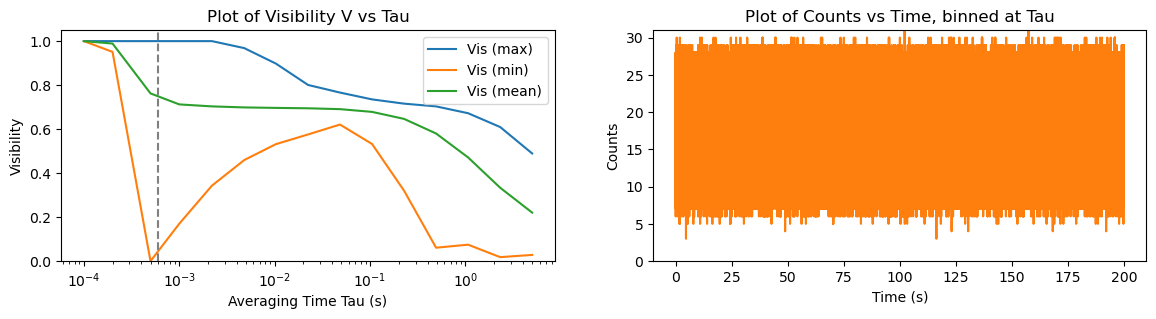

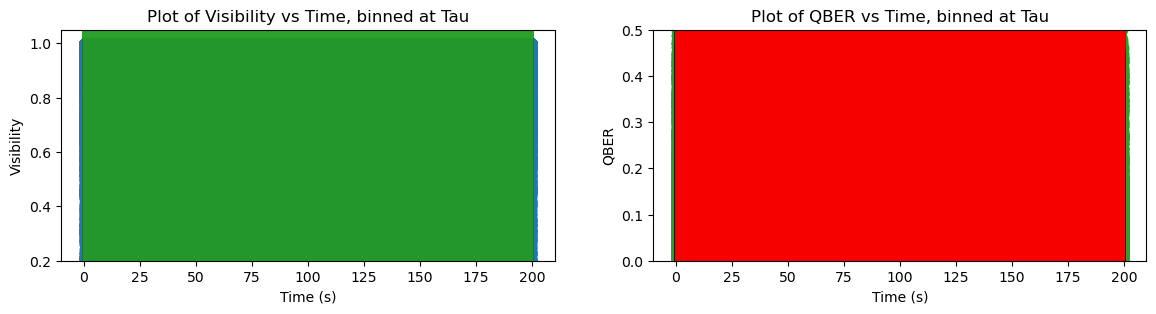

In [9]:
values2=Vis.AnalyseMeasurement2(ms,8,15,0.0006,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1518150 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.2150
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1532353 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.5949
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998466 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7623
τ[3] = 1.000e-03 s (K=  10, overlap_eff=0.50) -> 399999 windows, V_max= 1.0000, V_min= 0.1698, V_mean= 0.7124
τ[4] = 2.200e-03 s (K=  22, overlap_eff=0.50) -> 181817 windows, V_max= 1.0000, V_min= 0.3430, V_mean= 0.7034
τ[5] = 4.800e-03 s (K=  48, overlap_eff=0.50) -> 83332 windows, V_max= 0.9682, V_min= 0.4593, V_mean= 0.6987
τ[6] = 1.030e-02 s (K= 103, overlap_eff=0.50) -> 38460 windows, V_max= 0.8979, V_min= 0.5317, V_mean= 0.6965
τ[7] = 2.240e-02 s (K= 224, overlap_eff=0.50) -> 17856 windows, V_max= 0.8008, V_min= 0.5758, V_mean= 0.6947
τ[8] = 4.840e-02 s (K= 484, overlap_eff=0.50) -> 8263 windows, V_max= 0.7661, V_

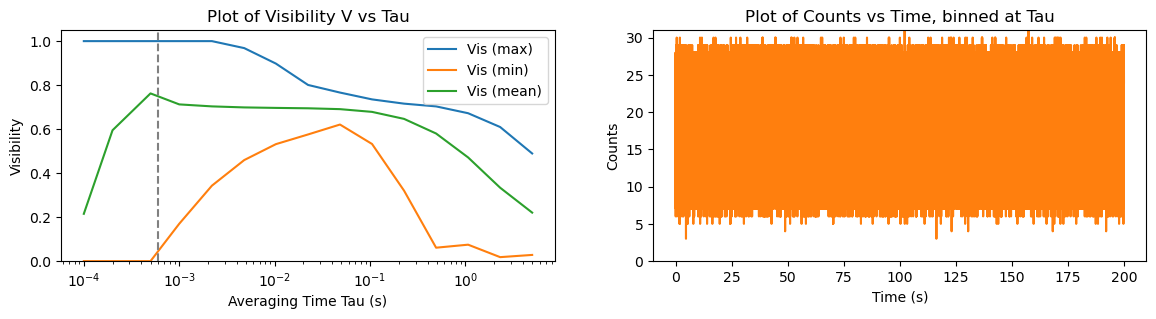

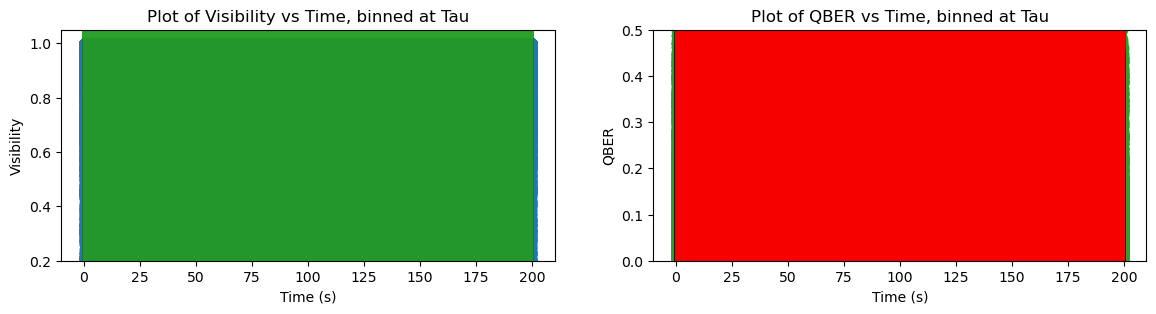

In [11]:
values3=Vis.AnalyseMeasurement2_fast(ms,8,15,0.0006,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

In [7]:
tau_max=5.0
log_bins=True
overlap=0.5
phase_offset=0.0
n_min=10
verbose=True

8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) ->    0 windows, V_max= nan, V_min= nan, V_mean= nan
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 160223 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.2689
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 805227 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7271
τ[3] = 1.000e-03 s (K=  10, overlap_eff=0.50) -> 399999 windows, V_max= 1.0000, V_min= 0.1698, V_mean= 0.7124
τ[4] = 2.200e-03 s (K=  22, overlap_eff=0.50) -> 181817 windows, V_max= 1.0000, V_min= 0.3430, V_mean= 0.7034
τ[5] = 4.800e-03 s (K=  48, overlap_eff=0.50) -> 83332 windows, V_max= 0.9682, V_min= 0.4593, V_mean= 0.6987
τ[6] = 1.030e-02 s (K= 103, overlap_eff=0.50) -> 38460 windows, V_max= 0.8979, V_min= 0.5317, V_mean= 0.6965
τ[7] = 2.240e-02 s (K= 224, overlap_eff=0.50) -> 17856 windows, V_max= 0.8008, V_min= 0.5758, V_mean= 0.6947
τ[8] = 4.840e-02 s (K= 484, overlap_eff=0.50) -> 8263 windows, V_max= 0.7661, V_min= 0.6208, 

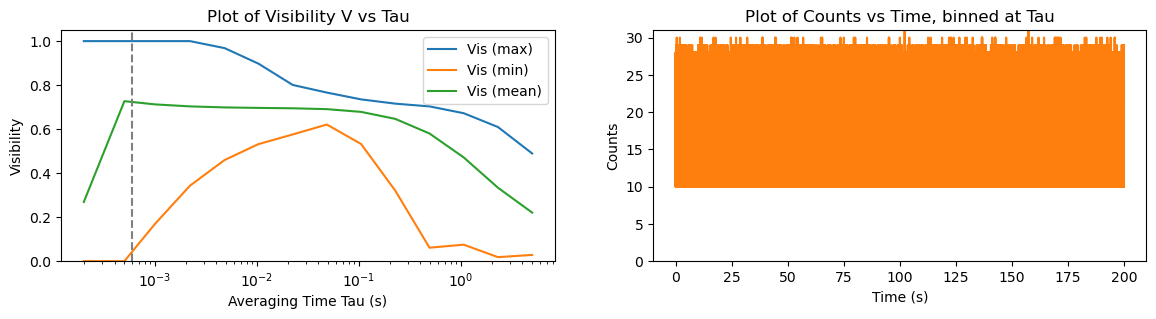

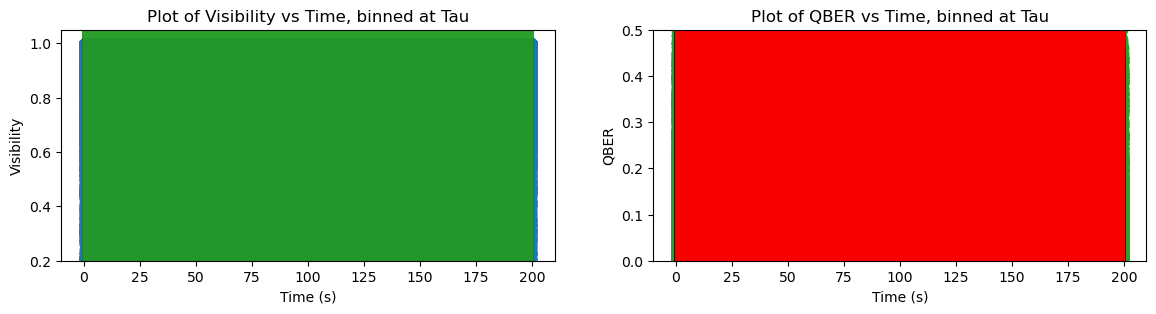

In [9]:
values4=Vis.AnalyseMeasurement2_fast(ms,8,15,0.0006,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

In [9]:
tau_max=10.0
log_bins=True
overlap=0.5
phase_offset=0.0
n_min=0
verbose=True

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1423172 windows, V_max= 1.0000, V_min= 0.0014, V_mean= 0.5735
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1475935 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7037
τ[2] = 3.000e-04 s (K=   3, overlap_eff=0.33) -> 708226 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7633
τ[3] = 4.000e-04 s (K=   4, overlap_eff=0.50) -> 929375 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7625
τ[4] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998573 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7592
τ[5] = 7.000e-04 s (K=   7, overlap_eff=0.43) -> 499999 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7330
τ[6] = 8.000e-04 s (K=   8, overlap_eff=0.50) -> 499999 windows, V_max= 1.0000, V_min= 0.0000, V_mean= 0.7200
τ[7] = 1.000e-03 s (K=  10, overlap_eff=0.50) -> 399999 windows, V_max= 1.0000, V_min= 0.1323, V_mean= 0.7090
τ[8] = 1.300e-03 s (K=  13, overlap_eff=0.54) -> 333332 windows,

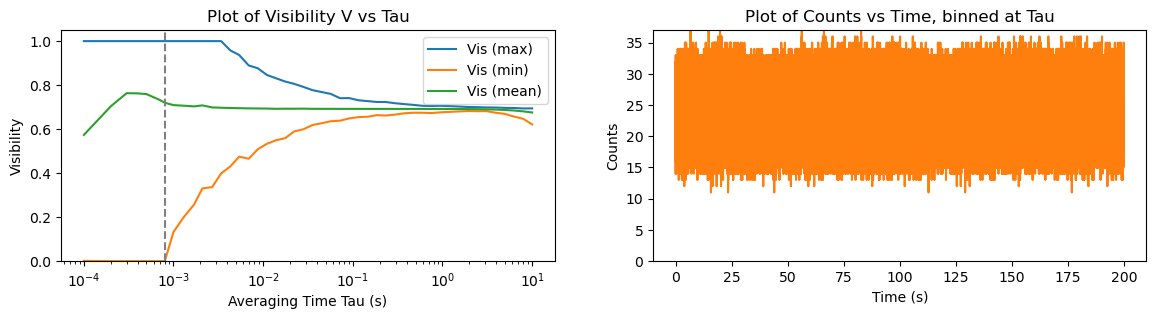

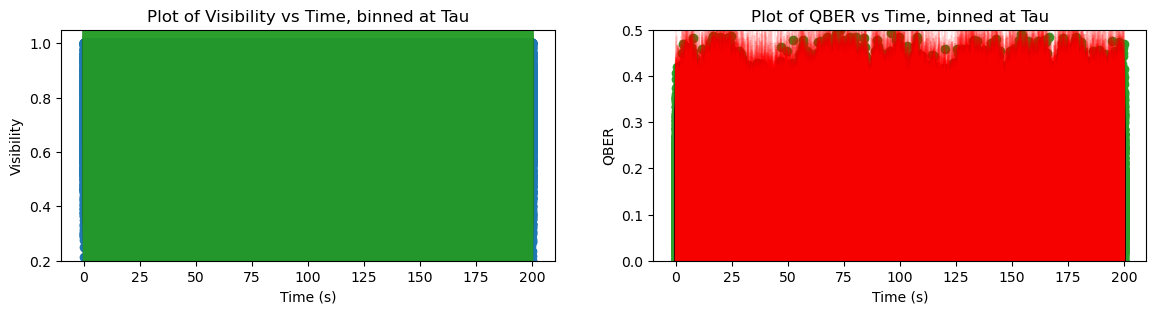

In [13]:
vms4=Vis.AnalyseMeasurement2_fast(ms,4,50,0.0008,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1423172 windows, V_max= 1.0000, V_min= 0.0014, V_mean= 0.5735
τ[1] = 1.800e-03 s (K=  18, overlap_eff=0.50) -> 222221 windows, V_max= 1.0000, V_min= 0.2098, V_mean= 0.7024
τ[2] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[3] = 5.623e-01 s (K=5623, overlap_eff=0.50) ->  710 windows, V_max= 0.7081, V_min= 0.6726, V_mean= 0.6918
τ[4] = 1.000e+01 s (K=100000, overlap_eff=0.50) ->   39 windows, V_max= 0.6942, V_min= 0.6213, V_mean= 0.6756


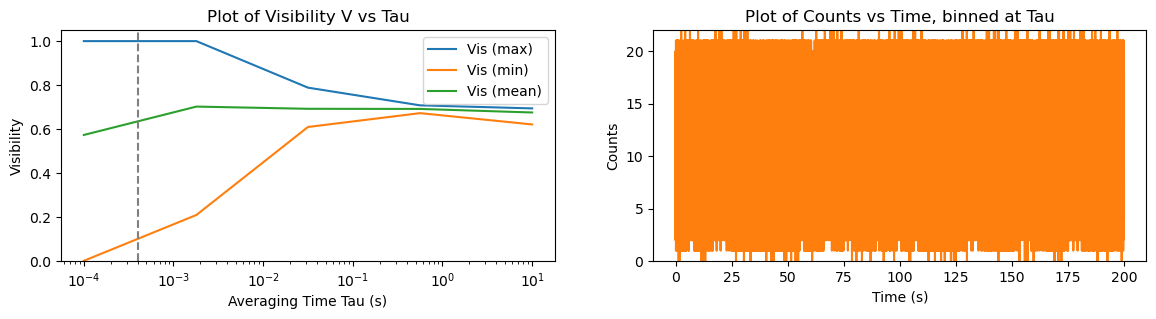

In [15]:
vms41=Vis.AnalyseMeasurement2_fast(ms,4,5,0.0004,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=False)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1423172 windows, V_max= 1.0000, V_min= 0.0014, V_mean= 0.5735
τ[1] = 1.800e-03 s (K=  18, overlap_eff=0.50) -> 222221 windows, V_max= 1.0000, V_min= 0.2098, V_mean= 0.7024
τ[2] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[3] = 5.623e-01 s (K=5623, overlap_eff=0.50) ->  710 windows, V_max= 0.7081, V_min= 0.6726, V_mean= 0.6918
τ[4] = 1.000e+01 s (K=100000, overlap_eff=0.50) ->   39 windows, V_max= 0.6942, V_min= 0.6213, V_mean= 0.6756


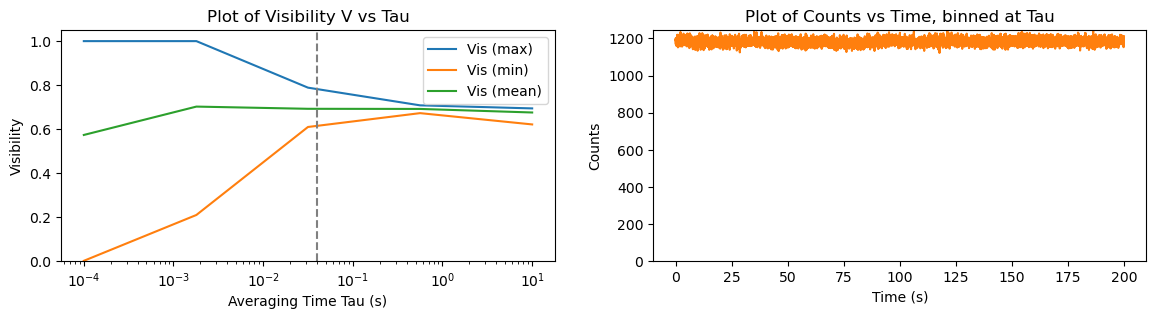

In [16]:
vms42=Vis.AnalyseMeasurement2_fast(ms,4,5,0.04,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=False)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1423172 windows, V_max= 8593401185362069.0000, V_min= 0.0014, V_mean= 19040219961.7638
τ[1] = 1.800e-03 s (K=  18, overlap_eff=0.50) -> 222221 windows, V_max= 1.1747, V_min= 0.2098, V_mean= 0.7025
τ[2] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[3] = 5.623e-01 s (K=5623, overlap_eff=0.50) ->  710 windows, V_max= 0.7081, V_min= 0.6726, V_mean= 0.6918
τ[4] = 1.000e+01 s (K=100000, overlap_eff=0.50) ->   39 windows, V_max= 0.6942, V_min= 0.6213, V_mean= 0.6756


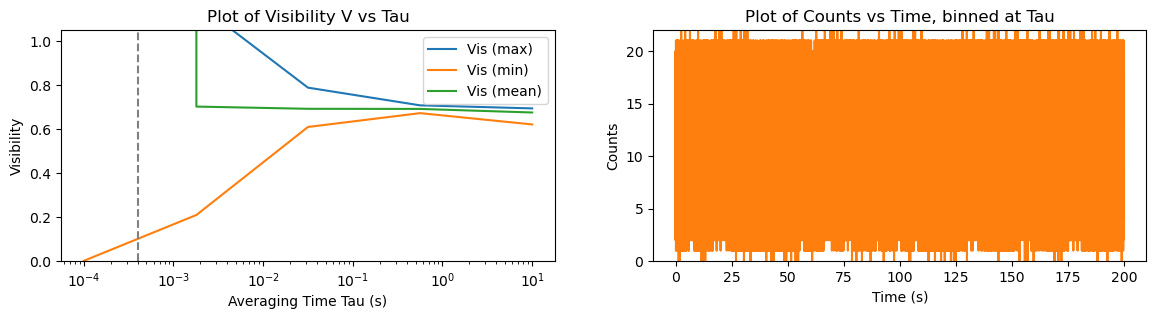

In [11]:
vms41=Vis.AnalyseMeasurement2_fast(ms,4,15,0.0004,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=False)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1423172 windows, V_max= 8593401185362069.0000, V_min= 0.0014, V_mean= 19040219961.7638
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1475935 windows, V_max= 168463.7326, V_min= 0.0000, V_mean= 2.8487
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998573 windows, V_max= 96.5530, V_min= 0.0000, V_mean= 1.1106
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 333332 windows, V_max= 1.3601, V_min= 0.1923, V_mean= 0.7078
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.48) -> 142856 windows, V_max= 1.0633, V_min= 0.3367, V_mean= 0.6987
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.51) -> 66665 windows, V_max= 0.9357, V_min= 0.4828, V_mean= 0.6975
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.50) -> 28570 windows, V_max= 0.8312, V_min= 0.5496, V_mean= 0.6923
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[8] = 7.200e-02 s (K= 720, overlap_

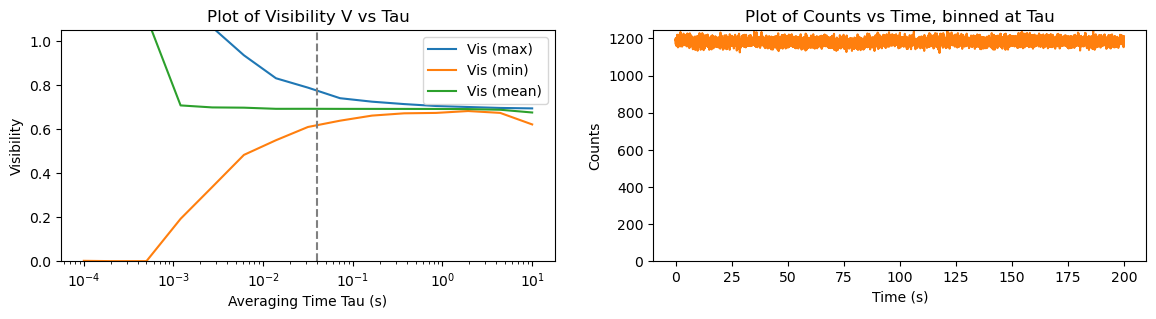

In [15]:
vms42=Vis.AnalyseMeasurement2_fast(ms,4,15,0.04,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=False)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1581260 windows, V_max= 162364.0809, V_min= 0.0001, V_mean= 1.5436
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1387257 windows, V_max= 672207.1125, V_min= 0.0000, V_mean= 3.9376
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998573 windows, V_max= 96.5530, V_min= 0.0000, V_mean= 1.1106
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 333332 windows, V_max= 1.3601, V_min= 0.1923, V_mean= 0.7078
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.48) -> 142856 windows, V_max= 1.0633, V_min= 0.3367, V_mean= 0.6987
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.51) -> 66665 windows, V_max= 0.9357, V_min= 0.4828, V_mean= 0.6975
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.50) -> 28570 windows, V_max= 0.8312, V_min= 0.5496, V_mean= 0.6923
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[8] = 7.200e-02 s (K= 720, overlap_eff=0.50) -> 5554 wi

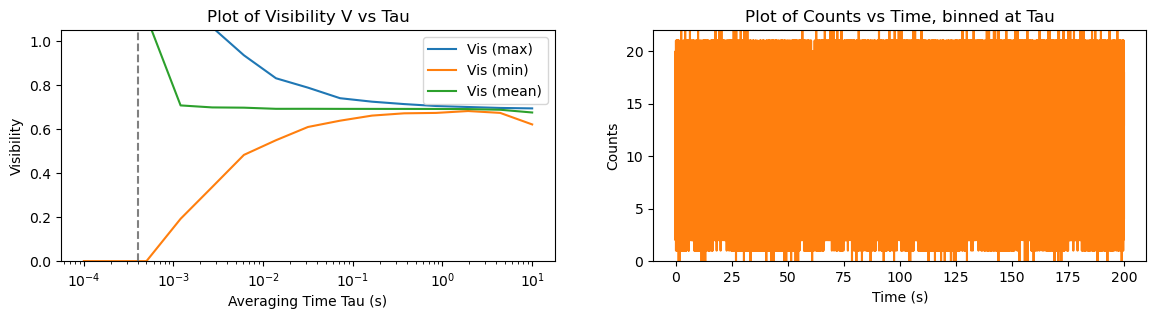

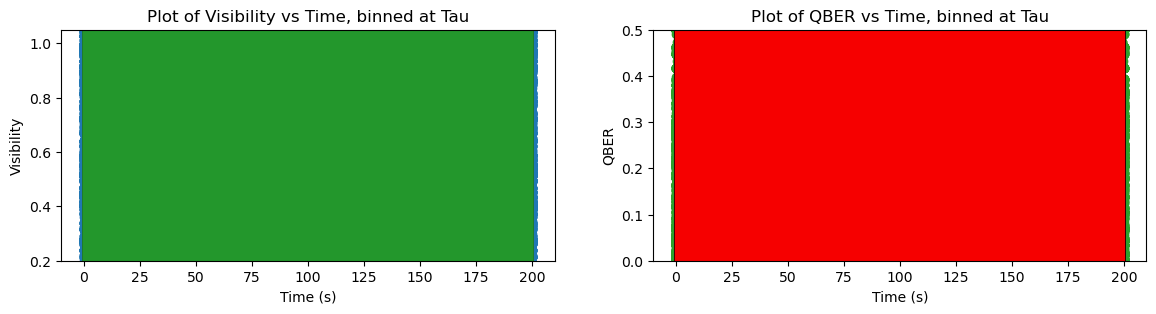

In [53]:
tau_max=10.0
log_bins=True
overlap=0.5
phase_offset=0.4
n_min=0
verbose=True
vms42=Vis.AnalyseMeasurement2_fast(ms,4,15,0.0004,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1588135 windows, V_max= 1288.9473, V_min= 0.0004, V_mean= 1.8279
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1404519 windows, V_max= 196953.5891, V_min= 0.0000, V_mean= 3.6550
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998573 windows, V_max= 96.5530, V_min= 0.0000, V_mean= 1.1106
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 333332 windows, V_max= 1.3601, V_min= 0.1923, V_mean= 0.7078
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.48) -> 142856 windows, V_max= 1.0633, V_min= 0.3367, V_mean= 0.6987
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.51) -> 66665 windows, V_max= 0.9357, V_min= 0.4828, V_mean= 0.6975
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.50) -> 28570 windows, V_max= 0.8312, V_min= 0.5496, V_mean= 0.6923
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[8] = 7.200e-02 s (K= 720, overlap_eff=0.50) -> 5554 wind

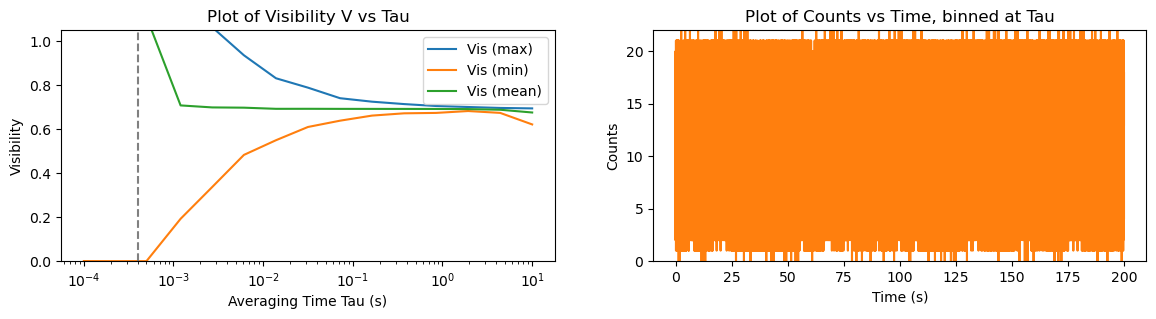

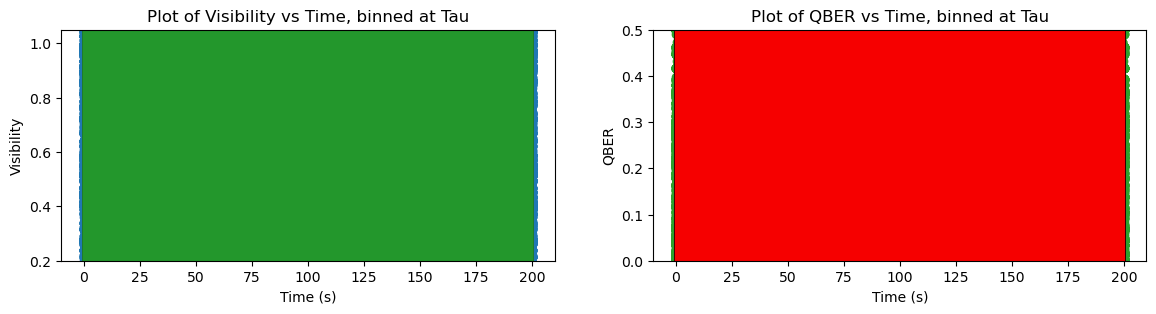

In [54]:
tau_max=10.0
log_bins=True
overlap=0.5
phase_offset=0.8
n_min=0
verbose=True
vms42=Vis.AnalyseMeasurement2_fast(ms,4,15,0.0004,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1569279 windows, V_max= 44476.6195, V_min= 0.0003, V_mean= 1.6434
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1400878 windows, V_max= 91840.8904, V_min= 0.0000, V_mean= 3.3651
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 998573 windows, V_max= 96.5530, V_min= 0.0000, V_mean= 1.1106
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 333332 windows, V_max= 1.3601, V_min= 0.1923, V_mean= 0.7078
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.48) -> 142856 windows, V_max= 1.0633, V_min= 0.3367, V_mean= 0.6987
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.51) -> 66665 windows, V_max= 0.9357, V_min= 0.4828, V_mean= 0.6975
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.50) -> 28570 windows, V_max= 0.8312, V_min= 0.5496, V_mean= 0.6923
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7885, V_min= 0.6097, V_mean= 0.6924
τ[8] = 7.200e-02 s (K= 720, overlap_eff=0.50) -> 5554 wind

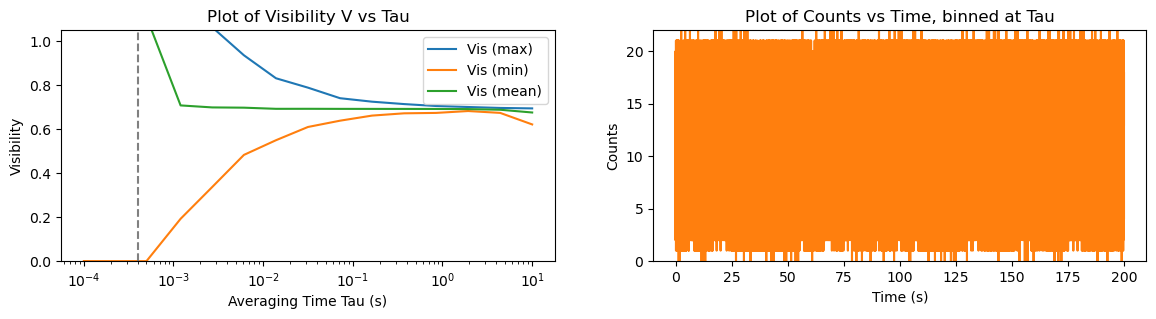

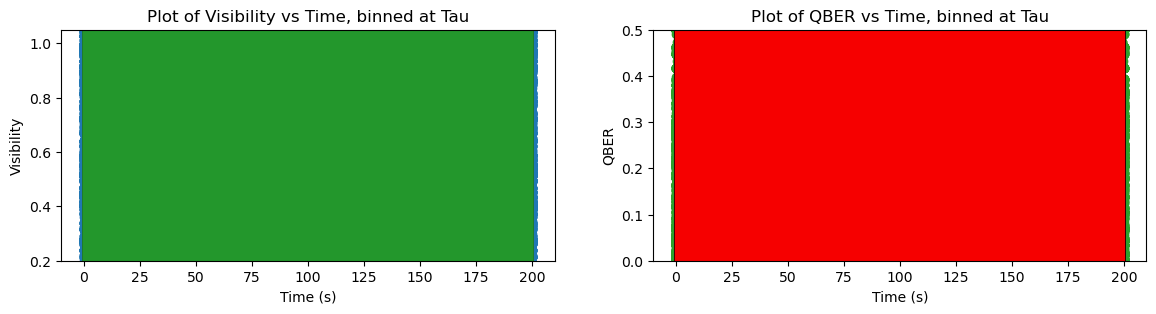

In [55]:
tau_max=10.0
log_bins=True
overlap=0.5
phase_offset=1.2
n_min=0
verbose=True
vms42=Vis.AnalyseMeasurement2_fast(ms,4,15,0.0004,0.001,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

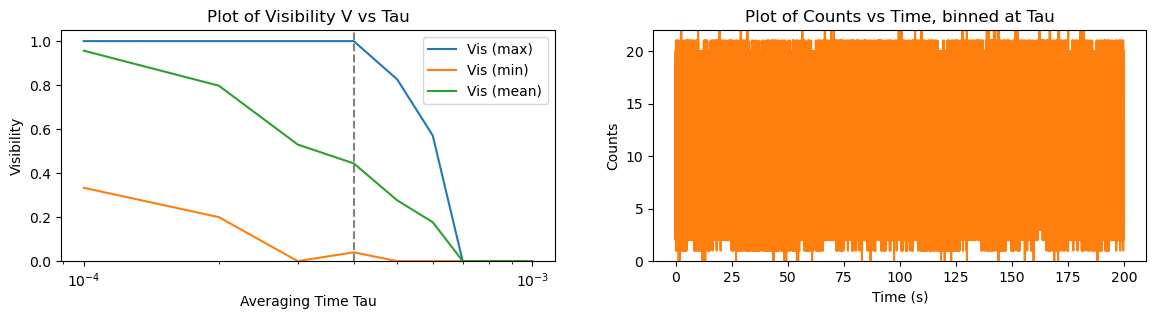

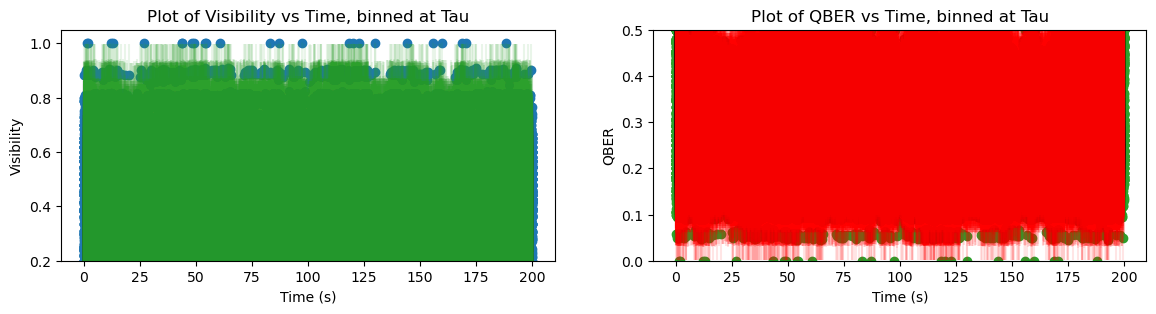

In [24]:
values1=Vis.AnalyseMeasurement(ms,4,100,0.0004,0.001,secondhalf=True)

In [33]:
vs=ms[4]['data']['pm_volts']

In [31]:
ts=Vis.timestamps_to_elapsed_seconds(ms[4]['data']['timestamps'])

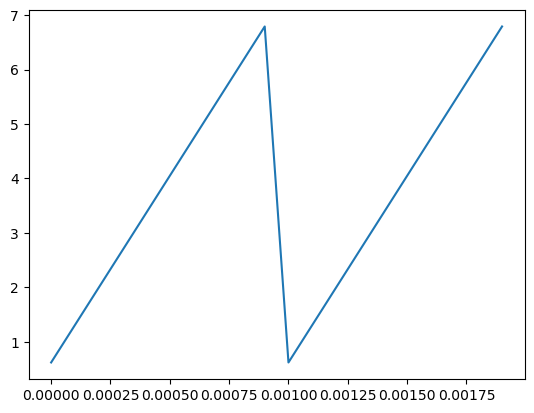

In [45]:
plt.plot(ts[0:20],vs[0:20])

In [47]:
cts=ms[4]['data']['counts']

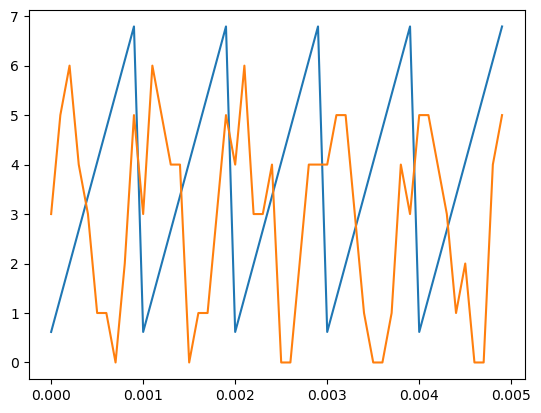

In [51]:
plt.plot(ts[0:50],vs[0:50])
plt.plot(ts[0:50],cts[0:50])

5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1537306 windows, V_max= 253530120045646316585554542592.0000, V_min= 0.0000, V_mean= 580734731157971279020032.0000
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.50) -> 1167457 windows, V_max= 844077.7206, V_min= 0.0000, V_mean= 4.9273
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.60) -> 536966 windows, V_max= 10.1580, V_min= 0.0000, V_mean= 1.1628
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.50) -> 205595 windows, V_max= 3950.3596, V_min= 0.0000, V_mean= 2.0870
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.48) -> 136232 windows, V_max= 1016712.2922, V_min= 0.0032, V_mean= 11.6309
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.51) -> 66665 windows, V_max= 1.3852, V_min= 0.1047, V_mean= 0.7465
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.50) -> 28570 windows, V_max= 0.8664, V_min= 0.5348, V_mean= 0.7073
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.50) -> 12657 windows, V_max= 0.7951, V_min= 0.6084, V_mean= 0.7059


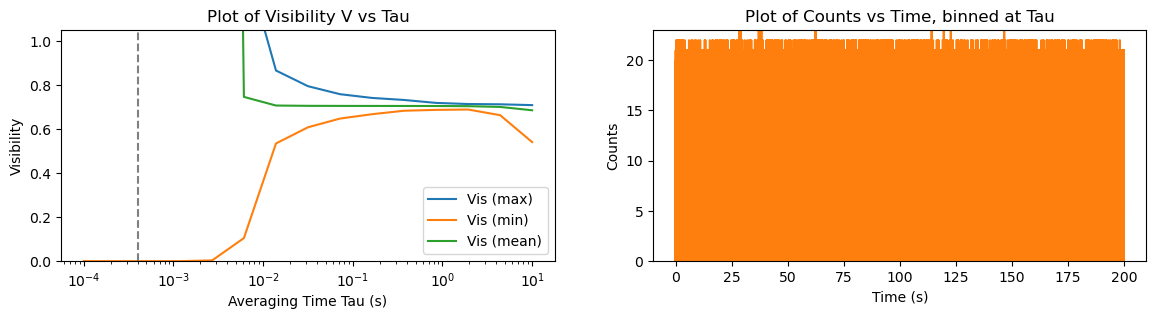

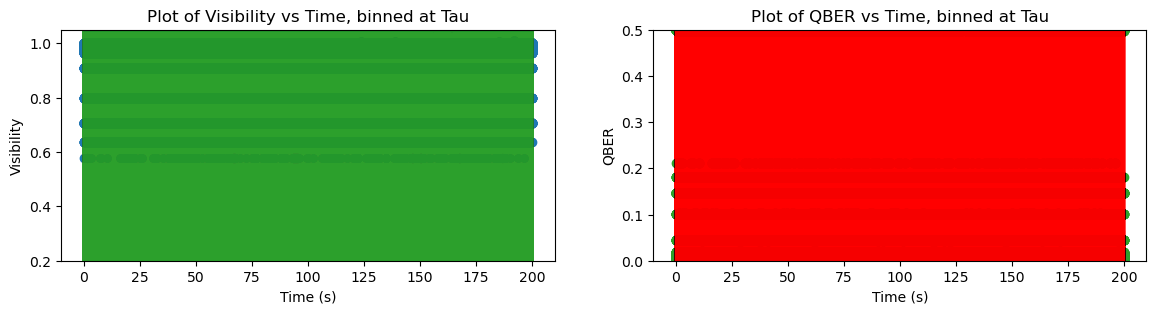

In [59]:
tau_max=10.0
log_bins=True
overlap=0.5
phase_offset=0
n_min=0
verbose=True
vms42=Vis.AnalyseMeasurement2_fast(ms,5,15,0.0004,0.01,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)

5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
τ[0] = 1.000e-04 s (K=   1, overlap_eff=0.00) -> 1537306 windows, V_max= 253530120045646316585554542592.0000, V_min= 0.0000, V_mean= 580734731157971279020032.0000
τ[1] = 2.000e-04 s (K=   2, overlap_eff=0.00) -> 583782 windows, V_max= 207577.4468, V_min= 0.0000, V_mean= 4.4531
τ[2] = 5.000e-04 s (K=   5, overlap_eff=0.00) -> 215436 windows, V_max= 10.1580, V_min= 0.0000, V_mean= 1.1596
τ[3] = 1.200e-03 s (K=  12, overlap_eff=0.08) -> 112232 windows, V_max= 24279.5978, V_min= 0.0000, V_mean= 2.4826
τ[4] = 2.700e-03 s (K=  27, overlap_eff=0.04) -> 73417 windows, V_max= 58624.4117, V_min= 0.0032, V_mean= 3.9815
τ[5] = 6.100e-03 s (K=  61, overlap_eff=0.05) -> 34482 windows, V_max= 1.3121, V_min= 0.1098, V_mean= 0.7472
τ[6] = 1.390e-02 s (K= 139, overlap_eff=0.05) -> 15151 windows, V_max= 0.8599, V_min= 0.5203, V_mean= 0.7073
τ[7] = 3.160e-02 s (K= 316, overlap_eff=0.05) -> 6666 windows, V_max= 0.8033, V_min= 0.6039, V_mean= 0.7142
τ[8] 

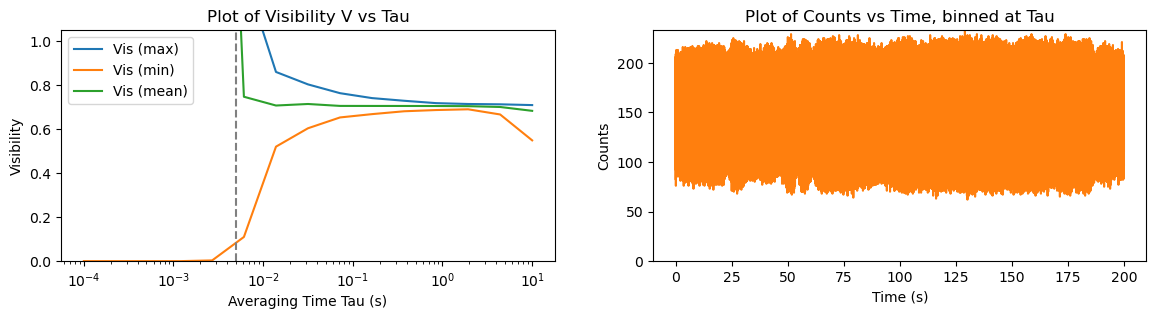

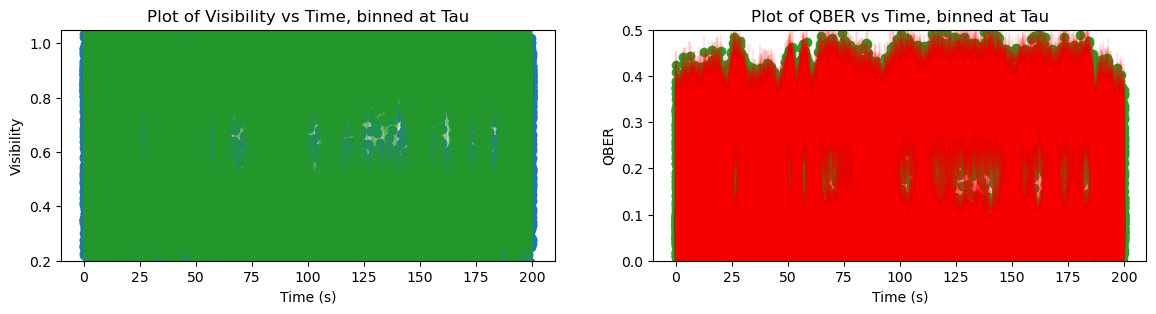

In [69]:
tau_max=10.0
log_bins=True
overlap=0.05
phase_offset=0
n_min=0
verbose=True
vms42=Vis.AnalyseMeasurement2_fast(ms,5,15,0.005,0.01,tau_max, overlap, phase_offset, n_min, verbose, firsthalf=True,secondhalf=True)